# What Drives Happiness Once the Factors Are Combined?

The other notebooks look at one factor at a time. But the factors move together (richer countries also
live longer and report more social support), so a single correlation can't say which one matters *on its own*.
This notebook fits all six factors together and asks four questions:

1. Which factors still matter with the other five held constant?
2. How much of happiness can be pinned on any single factor?
3. Which countries and regions are happier — or less happy — than their factors predict?
4. How solid are the top-20 / bottom-20 findings from `regional.ipynb`?

In [1]:
import sys
from pathlib import Path

# Make happiness.py importable whether Jupyter starts in JupyterCodes/ or the repo root
for folder in (Path.cwd(), Path.cwd().parent):
    if (folder / "happiness.py").exists():
        sys.path.insert(0, str(folder))
        break

import matplotlib.pyplot as plt
import pandas as pd
import happiness as hp

df = hp.load_data()
print(f"{len(df)} countries, {df[hp.REGION].nunique()} regions")

149 countries, 10 regions


## 1. The combined model

Standardized coefficients: change in ladder score (in standard deviations) per one-SD change in a factor, with the other five held constant. Intervals come from 2,000 bootstrap resamples of countries.

In [2]:
table, model = hp.regression_summary(df)
print(f"R² = {model['r2']:.3f} (adjusted {model['adj_r2']:.3f}), n = {model['n']}")
table.style.format({"beta": "{:.3f}", "p_value": "{:.4f}", "ci_low": "{:.3f}", "ci_high": "{:.3f}",
                    "unique_r2": "{:.3f}", "vif": "{:.2f}"})

R² = 0.756 (adjusted 0.746), n = 149


,factor,beta,p_value,ci_low,ci_high,unique_r2,vif
0,GDP,0.302,0.0016,0.108,0.483,0.018,5.10
1,Support,0.265,0.0003,0.111,0.431,0.024,2.97
2,Freedom,0.212,0.0001,0.113,0.306,0.028,1.59
3,Life Expectancy,0.191,0.0245,0.005,0.380,0.009,4.10
4,Perception of Corruption,-0.101,0.0391,-0.216,0.004,0.007,1.37
5,Generosity,0.051,0.2585,-0.046,0.155,0.002,1.18


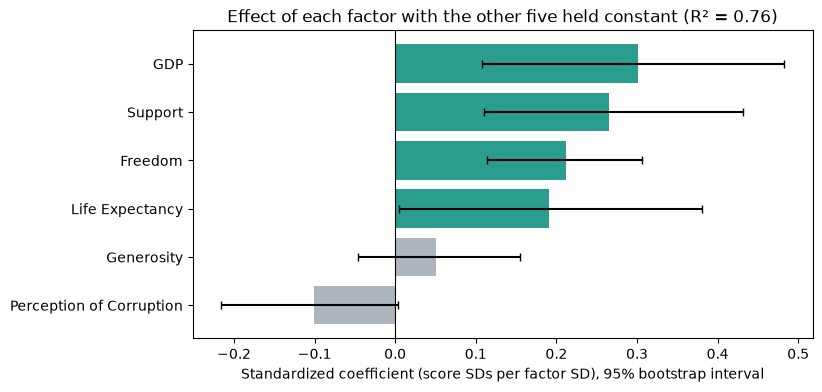

In [3]:
fig = hp.coefficient_chart(table, model)
hp.save(fig, "Drivers.png")
plt.show()

- The six factors explain about **76%** of the variation in happiness between countries.
- **GDP, social support and freedom** remain clearly positive with everything else held constant.
- **Healthy life expectancy** is positive but its interval nearly reaches zero: once wealth is known, health adds little.
- **Perceived corruption** is borderline (p ≈ 0.04, but the bootstrap interval touches zero).
- **Generosity** has no measurable effect, consistent with the simple correlation.
- VIFs are all below 10, so the overlap between factors (highest for GDP, ≈ 5) doesn't break the model, but it does widen the intervals.

## 2. How much can be pinned on a single factor?

*Unique R²* is how much explained variance is lost when one factor is dropped, i.e. what only that factor explains.

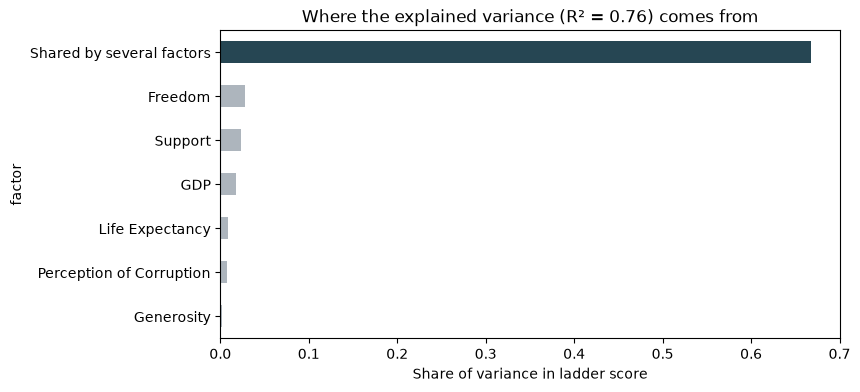

Shared: 0.667 of 0.756 → 88% of what the model explains


In [4]:
parts = table.set_index("factor")["unique_r2"].sort_values()
parts["Shared by several factors"] = model["shared_r2"]
ax = parts.plot.barh(figsize=(8, 4), color=["#adb5bd"] * (len(parts) - 1) + ["#264653"])
ax.set(title=f"Where the explained variance (R² = {model['r2']:.2f}) comes from", xlabel="Share of variance in ladder score")
plt.show()
print(f"Shared: {model['shared_r2']:.3f} of {model['r2']:.3f} → {model['shared_r2'] / model['r2']:.0%} of what the model explains")

About **88% of the explained variance is shared**: happiness tracks a *bundle* of wealth, health and support,
and the data can't cleanly separate them. **Freedom** has the largest unique share (≈ 2.8%) even though its simple
correlation is the weakest of the four big factors, because it overlaps least with the others (lowest VIF among them).
For policy readers, the takeaway is that no single lever explains national happiness.

## 3. Happier than expected?

Residual = actual score − score predicted from the six factors.

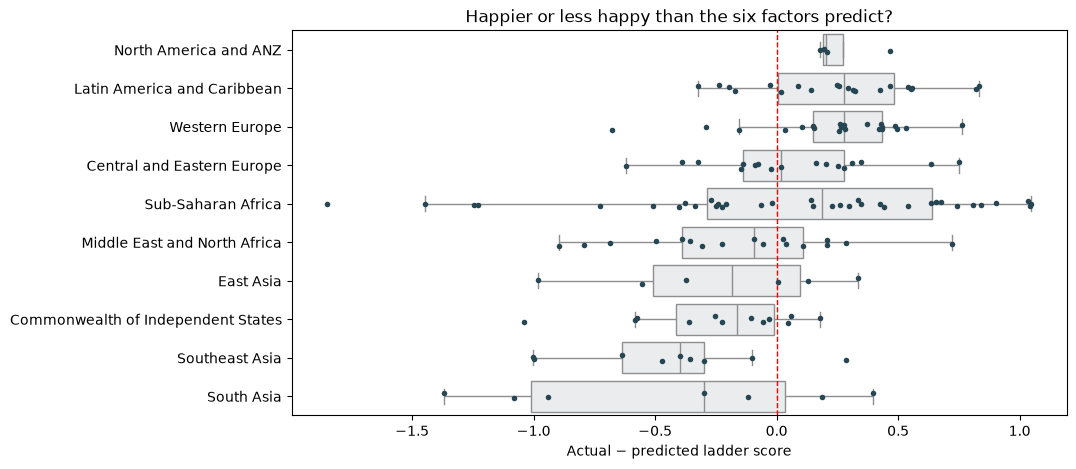

In [5]:
fig = hp.residual_chart(df)
hp.save(fig, "Residuals.png")
plt.show()

In [6]:
regions, anova_p = hp.regional_residuals(df)
print(f"Do residuals differ by region? one-way ANOVA p = {anova_p:.4f}")
regions.style.format({"mean_residual": "{:+.2f}", "share_above_prediction": "{:.0%}", "p_value": "{:.3f}", "p_adjusted": "{:.3f}"})

Do residuals differ by region? one-way ANOVA p = 0.0007


,Regional indicator,countries,mean_residual,share_above_prediction,p_value,p_adjusted
0,North America and ANZ,4,+0.26,100%,0.031,0.314
1,Latin America and Caribbean,20,+0.25,75%,0.004,0.039
2,Western Europe,21,+0.24,86%,0.002,0.024
3,Central and Eastern Europe,17,+0.07,53%,0.440,1.000
4,Sub-Saharan Africa,36,+0.06,56%,0.625,1.000
5,Middle East and North Africa,17,-0.16,41%,0.140,1.000
6,East Asia,6,-0.24,50%,0.282,1.000
7,Commonwealth of Independent States,12,-0.25,25%,0.032,0.322
8,Southeast Asia,9,-0.44,11%,0.012,0.118
9,South Asia,7,-0.46,29%,0.121,1.000


In [7]:
pred = hp.add_predictions(df)
cols = ["Country name", hp.REGION, hp.SCORE, "predicted", "residual"]
print("Happier than predicted"); display(pred.nlargest(8, "residual")[cols].round(2))
print("Less happy than predicted"); display(pred.nsmallest(8, "residual")[cols].round(2))

Happier than predicted


,Country name,Regional indicator,Ladder score,predicted,residual
82,Congo (Brazzaville),Sub-Saharan Africa,5.34,4.29,1.05
98,Benin,Sub-Saharan Africa,5.04,4.00,1.04
84,Ivory Coast,Sub-Saharan Africa,5.31,4.27,1.04
95,Niger,Sub-Saharan Africa,5.07,4.17,0.90
127,Chad,Sub-Saharan Africa,4.36,3.51,0.84
15,Costa Rica,Latin America and Caribbean,7.07,6.24,0.83
29,Guatemala,Latin America and Caribbean,6.44,5.61,0.82
101,Guinea,Sub-Saharan Africa,4.98,4.18,0.81


Less happy than predicted


,Country name,Regional indicator,Ladder score,predicted,residual
145,Botswana,Sub-Saharan Africa,3.47,5.32,-1.85
146,Rwanda,Sub-Saharan Africa,3.42,4.86,-1.45
128,Sri Lanka,South Asia,4.32,5.70,-1.37
147,Zimbabwe,Sub-Saharan Africa,3.14,4.39,-1.25
141,Tanzania,Sub-Saharan Africa,3.62,4.85,-1.23
138,India,South Asia,3.82,4.90,-1.08
96,Turkmenistan,Commonwealth of Independent States,5.07,6.11,-1.04
31,Singapore,Southeast Asia,6.38,7.38,-1.00


- Residuals differ by region well beyond chance (ANOVA p < 0.001).
- **Latin America** (+0.25; 15 of 20 countries above prediction) and **Western Europe** (+0.24; 18 of 21) are
  happier than their factors predict, and both hold up after correcting for testing ten regions.
- **Southeast Asia** sits below prediction in 8 of 9 countries (−0.44), suggestive but not significant after correction;
  South Asia shows the same direction with only 7 countries.
- Possible explanations include cultural differences in how people answer life-evaluation questions, and things the
  six factors don't measure (family ties, inequality, recent shocks). The data can't distinguish these.

## 4. How solid are the top-20 / bottom-20 findings?

In [8]:
top, bottom = hp.top_and_bottom(df, 20)
fmt = {"correlation": "{:.2f}", "p_value": "{:.3f}", "ci_low": "{:.2f}", "ci_high": "{:.2f}"}
print("20 happiest countries"); display(hp.subgroup_correlations(top).style.format(fmt))
print("20 least happy countries"); display(hp.subgroup_correlations(bottom).style.format(fmt))
print(f"Spread of ladder score — all: {df[hp.SCORE].std():.2f}, top 20: {top[hp.SCORE].std():.2f}, bottom 20: {bottom[hp.SCORE].std():.2f}")

20 happiest countries


,factor,correlation,p_value,ci_low,ci_high
0,GDP,0.23,0.327,-0.24,0.61
1,Support,0.58,0.008,0.18,0.81
2,Life Expectancy,0.37,0.104,-0.08,0.70
3,Freedom,0.73,0.000,0.43,0.89
4,Generosity,0.17,0.481,-0.30,0.57
5,Perception of Corruption,-0.65,0.002,-0.85,-0.30


20 least happy countries


,factor,correlation,p_value,ci_low,ci_high
0,GDP,0.19,0.433,-0.28,0.58
1,Support,0.36,0.115,-0.09,0.69
2,Life Expectancy,0.20,0.395,-0.27,0.59
3,Freedom,0.11,0.654,-0.35,0.52
4,Generosity,0.03,0.894,-0.42,0.47
5,Perception of Corruption,-0.00,0.985,-0.45,0.44


Spread of ladder score — all: 1.07, top 20: 0.26, bottom 20: 0.46


- Among the happiest 20, **freedom** (r = 0.73) and **perceived corruption** (r = −0.65) are significant, but with
  only 20 countries the 95% intervals are wide (freedom 0.43–0.89).
- **No factor** is significant among the least happy 20.
- Scores vary much less inside each group (spread 0.26 for the top 20 and 0.46 for the bottom 20, vs 1.07 overall),
  which by itself pushes correlations toward zero. Treat these subgroup results as directional.

## Robustness: rank correlations

Spearman correlations don't depend on straight-line relationships or extreme values.

In [9]:
robust = pd.DataFrame({
    "pearson": df[[*hp.FACTORS]].corrwith(df[hp.SCORE]),
    "spearman": df[[*hp.FACTORS]].corrwith(df[hp.SCORE], method="spearman"),
}).rename(index=hp.FACTORS).round(3)
robust

,pearson,spearman
GDP,0.790,0.809
Support,0.757,0.798
Life Expectancy,0.768,0.797
Freedom,0.608,0.607
Generosity,-0.018,-0.008
Perception of Corruption,-0.421,-0.301


The ranking of factors is unchanged. Perceived corruption is weaker by rank (≈ −0.30 vs −0.42),
so part of its linear correlation comes from a handful of very-low-corruption, very happy countries (mostly Nordic).